# Cell-type deconvolution of Visium spots with RCTD

We load a pregrown tumor, cut the resected tumor in two, and measure one half by single-cell RNA sequencing (scRNA-seq) and a section of a lesion in the other half by 10x Visium.
We then deconvolve the Visium spots into cell types with RCTD ([Cable et al. 2022](https://github.com/dmcable/spacexr)), using the scRNA-seq data of the same tumor as the reference, and compare its cell-type proportions per spot with the true proportions, which the ground truth holds, since `iscc` tracks the cells in each spot.

RCTD runs in its own conda environment, `iscc-rctd`, from a short R script that the notebook writes and runs with that environment's `Rscript`.

In [1]:
import os
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import iscc.pregrown
from iscc.data import Visium, scRNA
from iscc.data.human import HumanGenomeLayer, write_scrna, write_visium
from iscc.integrations import cell_subtypes
from iscc.sample import Resection

RSCRIPT = os.path.expanduser("~/miniconda3/envs/iscc-rctd/bin/Rscript")
os.chdir(tempfile.mkdtemp())        # the data and the tool's outputs go to a scratch directory

## The pregrown tumor with immune cells

We load the pregrown tumor with immune cells ([`iscc.pregrown.immune`](https://pedrofale.github.io/iscc/reference/#pregrown-tumors)), the tumor of the paper's regime grown with T and NK cells, myeloid cells and B and plasma cells in the stroma, beside its fibroblasts, endothelial cells and perivascular cells, and with immune killing of cancer cells there.
It took 538 generations to reach 200,064 cancer cells on a field of 1 cm, against 299 for the tumor without immune cells.
Two large lesions grew from the glands, other glands still hold tumors in situ, and every cancer cell has a doubled genome.
Its genome has one segment per chromosome arm ([`arm_genome`](https://pedrofale.github.io/iscc/reference/arm_genome/)), which [`HumanGenomeLayer`](https://pedrofale.github.io/iscc/reference/HumanGenomeLayer/) maps onto the human genome, and the epithelium is its cell of origin, so that cancer cells share the expression baseline of normal epithelial cells and differ from them only by what evolution did to them.

200,064 cancer cells after 538 generations


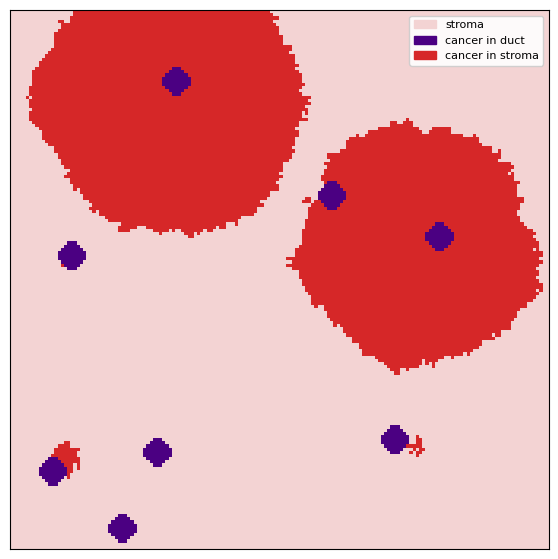

In [2]:
tumor = iscc.pregrown.immune()
print(f"{tumor.get_cancer_size():,} cancer cells after {tumor.time:.0f} generations")
tumor.plot_tissue();

## Two samples of one resection

[`Resection`](https://pedrofale.github.io/iscc/reference/Resection/) cuts the specimen in the plane into two halves, as a pathologist would, here into the upper and the lower half of the map.
We dissociate the upper half, which holds most of the two lesions, into about 8,000 cells for scRNA-seq.
From the lower half we cut a thin section around its cancer cells, from a window of 64 by 64 demes centered on them ([`primary_window`](https://pedrofale.github.io/iscc/reference/GenotypeTumor/)), keeping half of the depth of each deme, so that the section is about one cell layer thick.
The section holds the lower edge of the lesion on the right and a gland with a tumor in situ.
The tumor caps every sample at a few thousand cells (`max_cells`), so we raise the cap for the section, letting its thickness set the number of cells.

In [3]:
specimen = Resection(tumor)
upper_half, lower_half = specimen.bisect(frac=0.5, axis="y")
lower_tumor = sorted(set(specimen.cancer_region(margin=0)) & set(lower_half))
center = tuple(int(x) for x in np.mean([tumor.deme_coords[d] for d in lower_tumor], axis=0))
lesion = sorted(set(tumor.primary_window(side=64, center=center)) & set(lower_half))
upper_tumor = sorted(set(specimen.cancer_region(margin=1)) & set(upper_half))
cells = specimen.dissociate(upper_tumor, max_cells=8000)
section = specimen.slice(lesion, depth_frac=0.5, max_cells=100_000, layers="visium")
for name, sample in [("dissociated", cells), ("section", section)]:
    types = pd.Series(cell_subtypes(sample["cell_type"].iloc[:, 0])).value_counts()
    print(f"{name:>12}: {types.sum():,} cells,", types.to_dict())

 dissociated: 8,106 cells, {'cancer': 5199, 'endothelial': 952, 'fibroblast': 830, 'PVL': 719, 'epithelial': 148, 'T_NK': 147, 'myeloid': 82, 'B_plasma': 29}
     section: 32,620 cells, {'cancer': 11576, 'endothelial': 5645, 'fibroblast': 4757, 'PVL': 3844, 'T_NK': 3778, 'myeloid': 2029, 'B_plasma': 732, 'epithelial': 259}


We measure the section with [`Visium`](https://pedrofale.github.io/iscc/reference/Visium/), with its default spots of 55 µm on a square capture area the size of the section, and the dissociated cells with the 10x Genomics preset of [`scRNA`](https://pedrofale.github.io/iscc/reference/scRNA/), both over the human genes.
With `section_frac=1.0`, Visium places the cells of each deme at positions inside it and centers the section on the capture area, without thinning the section again.
[`write_visium`](https://pedrofale.github.io/iscc/reference/write_visium/) and [`write_scrna`](https://pedrofale.github.io/iscc/reference/write_scrna/) write the data as Space Ranger and Cell Ranger output, with the ground truth in a separate `truth` folder that no tool reads.

In [4]:
layer = HumanGenomeLayer(tumor)
expression = layer.expression(tumor)
visium = Visium(seed=1, section_frac=1.0).run(section, grid_side=64, gene_lift=expression)
write_visium("visium", visium, layer, tumor=tumor)
rna = scRNA(protocol="10x", n_cells=len(cells["cell_exp"]), seed=1).run(cells, gene_lift=expression)
write_scrna("scrna", rna, layer, cells, tumor=tumor)

in_tissue = visium.obs["n_cells"] > 0
print(f"Visium: {in_tissue.sum():,} spots over the tissue, a median of {visium.obs.loc[in_tissue, 'n_cells'].median():.0f} "
      f"cells and {visium.obs.loc[in_tissue, 'n_counts'].median():,.0f} UMIs per spot")
print(f"scRNA: {rna.obs.shape[0]:,} cells, a median of {rna.obs['n_counts'].median():,.0f} UMIs per cell")

Visium: 891 spots over the tissue, a median of 9 cells and 14,746 UMIs per spot
scRNA: 8,106 cells, a median of 3,986 UMIs per cell


RCTD needs the cell type of each reference cell.
A user annotates the microenvironment from marker genes, the stromal cells by subtype (fibroblasts, endothelial cells and perivascular cells, PVL) and the immune cells by subtype (T and NK, myeloid, B and plasma cells), and tells cancer cells from normal epithelial cells by copy number, for example with inferCNV as in [the scRNA copy-number tutorial](tool_scrna_cnv.ipynb).
Here we take the cell types from the ground truth, which stands for an annotation without errors, and leave out the doublets.

In [5]:
cell_truth = pd.read_csv("scrna/truth/cells.tsv", sep="\t", index_col="barcode", dtype={"genotype": str})
cell_truth["cell_type"] = cell_subtypes(cell_truth["genotype"])
cell_truth.loc[~cell_truth["is_doublet"], ["cell_type"]].to_csv("reference_cell_types.csv")
cell_truth.loc[~cell_truth["is_doublet"], "cell_type"].value_counts().to_dict()

{'cancer': 4921,
 'endothelial': 913,
 'fibroblast': 803,
 'PVL': 680,
 'T_NK': 139,
 'epithelial': 139,
 'myeloid': 78,
 'B_plasma': 28}

## RCTD

The script below runs spacexr's standard workflow, which builds a `Reference` from the annotated scRNA-seq counts and a `SpatialRNA` from the Visium counts and the spot positions, and runs `run.RCTD`.
RCTD runs in full mode, which fits any mixture of cell types in a spot, as spacexr's documentation recommends for technologies with large spots such as Visium.
It runs on one core (`max_cores = 1`), since its parallel workers failed intermittently on our laptop and one core is about as fast at this size, and every other setting is the default.
The counts are read from the Cell Ranger and Space Ranger matrix directories with the Matrix package.

In [6]:
%%writefile run_rctd.R
suppressMessages({library(spacexr); library(Matrix)})

read_10x <- function(dir) {           # a filtered_feature_bc_matrix directory of Cell Ranger or Space Ranger
  counts <- readMM(file.path(dir, "matrix.mtx.gz"))
  rownames(counts) <- make.unique(read.delim(file.path(dir, "features.tsv.gz"), header = FALSE)[[2]])
  colnames(counts) <- read.delim(file.path(dir, "barcodes.tsv.gz"), header = FALSE)[[1]]
  as(counts, "CsparseMatrix")
}

ref_counts <- read_10x("scrna/outs/filtered_feature_bc_matrix")
annotation <- read.csv("reference_cell_types.csv", row.names = 1)
ref_counts <- ref_counts[, rownames(annotation)]
cell_types <- factor(annotation$cell_type, levels = sort(unique(annotation$cell_type)))
names(cell_types) <- rownames(annotation)
reference <- Reference(ref_counts, cell_types)

spot_counts <- read_10x("visium/outs/filtered_feature_bc_matrix")
positions <- read.csv("visium/outs/spatial/tissue_positions.csv", row.names = 1)
coords <- positions[colnames(spot_counts), c("pxl_col_in_fullres", "pxl_row_in_fullres")]
colnames(coords) <- c("x", "y")
puck <- SpatialRNA(coords, spot_counts)

rctd <- create.RCTD(puck, reference, max_cores = 1)
rctd <- run.RCTD(rctd, doublet_mode = "full")
proportions <- as.matrix(normalize_weights(rctd@results$weights))
write.csv(proportions, "rctd_proportions.csv")
cat(sprintf("spacexr %s: %d spots and %d cell types\n", packageVersion("spacexr"), nrow(proportions), ncol(proportions)))

Writing run_rctd.R


In [7]:
!{RSCRIPT} run_rctd.R > rctd.log 2>&1; tail -n 1 rctd.log

spacexr 2.2.1: 891 spots and 8 cell types


## RCTD recovers where each cell type lies

We read the true proportion of each cell type in each spot from the cells that the ground truth lists for the spot.
We compare RCTD's proportions with these over the spots RCTD fitted, through the Pearson correlation and the mean absolute error for each cell type.

In [8]:
spots = pd.read_csv("visium/truth/spots.tsv", sep="\t", index_col="barcode", dtype={"genotypes": str})
spot_cells = spots["genotypes"].dropna().str.split(",").explode()
true_prop = pd.crosstab(spot_cells.index, cell_subtypes(spot_cells), normalize="index")
rctd = pd.read_csv("rctd_proportions.csv", index_col=0)
true_prop = true_prop.reindex(index=rctd.index, columns=rctd.columns, fill_value=0.0)

pd.DataFrame({"mean true proportion": true_prop.mean(), "mean RCTD proportion": rctd.mean(),
              "Pearson r": rctd.corrwith(true_prop),
              "mean absolute error": (rctd - true_prop).abs().mean()}).round(2)

,mean true proportion,mean RCTD proportion,Pearson r,mean absolute error
B_plasma,0.03,0.03,0.99,0.01
PVL,0.13,0.09,0.94,0.05
T_NK,0.15,0.09,0.97,0.06
cancer,0.26,0.32,0.99,0.06
endothelial,0.20,0.17,0.94,0.05
epithelial,0.00,0.02,0.62,0.02
fibroblast,0.16,0.16,0.94,0.04
myeloid,0.08,0.12,0.99,0.04


The maps show the true proportion of each cell type per spot (top) and RCTD's (bottom).

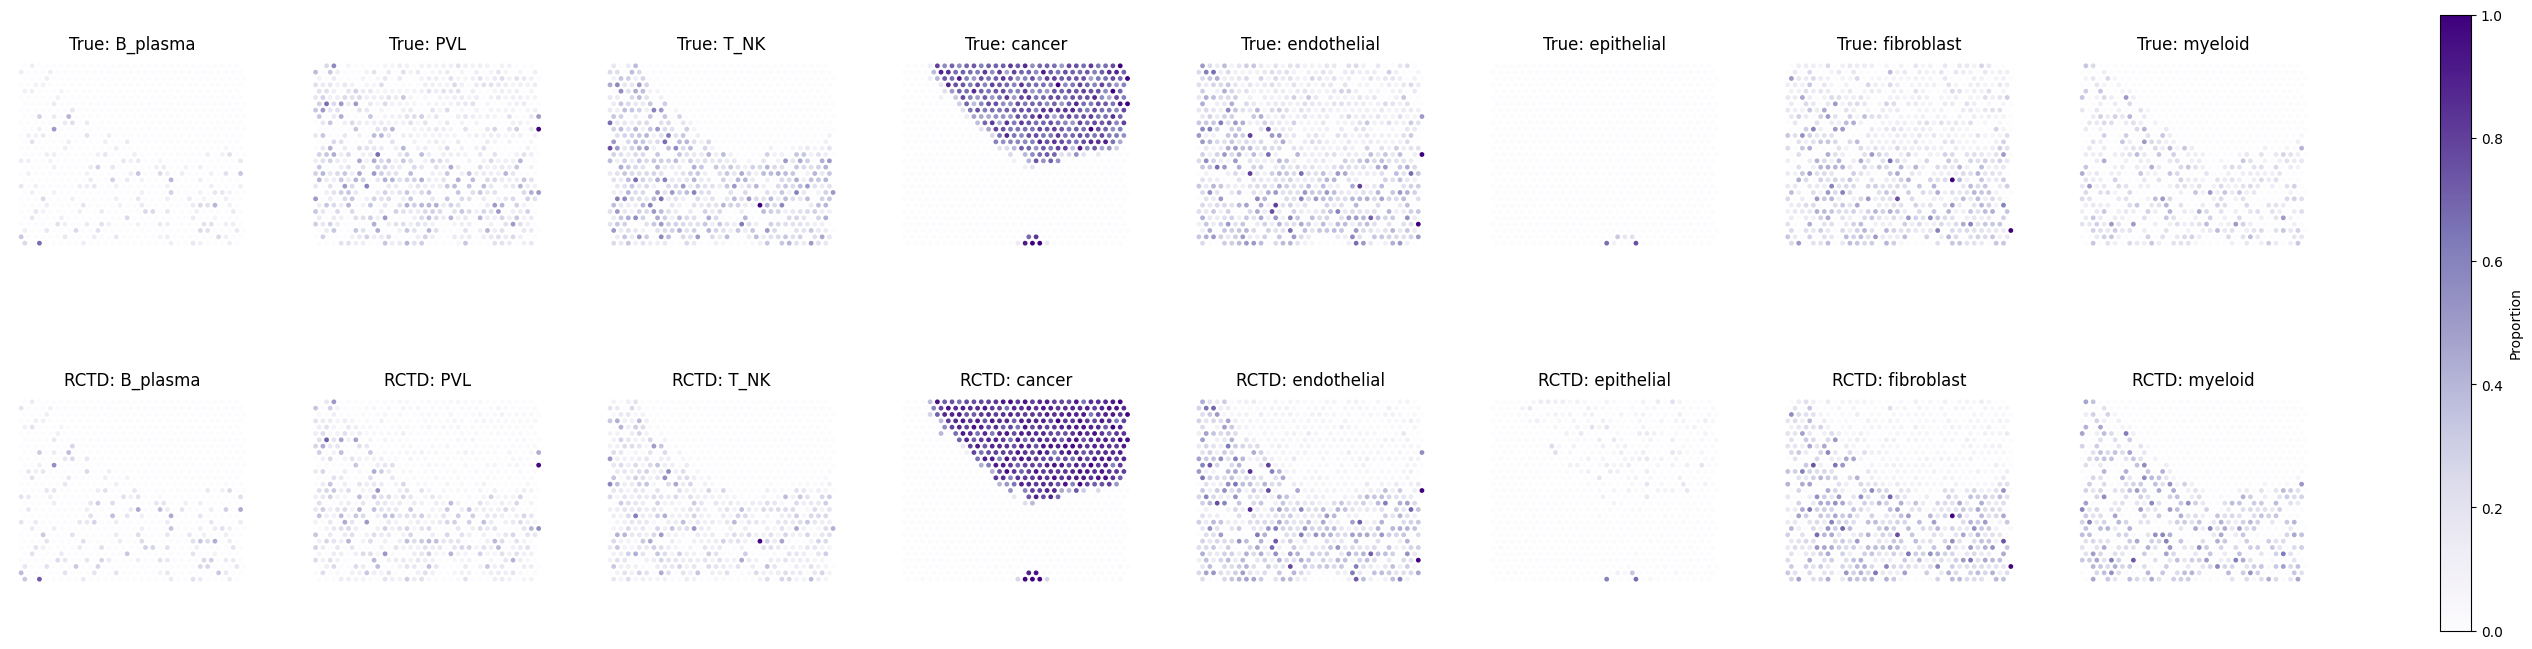

In [9]:
xy = pd.read_csv("visium/outs/spatial/tissue_positions.csv", index_col=0).loc[rctd.index]
fig, axes = plt.subplots(2, len(rctd.columns), figsize=(4 * len(rctd.columns), 8))
for row, (label, values) in enumerate([("True", true_prop), ("RCTD", rctd)]):
    for col, cell_type in enumerate(rctd.columns):
        ax = axes[row, col]
        im = ax.scatter(xy["pxl_col_in_fullres"], xy["pxl_row_in_fullres"], c=values[cell_type], s=6,
                        cmap="Purples", vmin=0, vmax=1)
        ax.set_title(f"{label}: {cell_type}")
        ax.set_aspect("equal")
        ax.invert_yaxis()
        ax.axis("off")
fig.colorbar(im, ax=axes, fraction=0.02, label="Proportion")
plt.show()

RCTD's proportions followed the true ones closely for seven of the eight cell types, with Pearson correlations between 0.94 and 0.99.
RCTD overestimated the proportions of cancer cells (0.32 against 0.26 on average) and myeloid cells (0.12 against 0.08), and underestimated those of T and NK cells (0.09 against 0.15), perivascular cells (0.09 against 0.13) and endothelial cells (0.17 against 0.20).
Normal epithelial cells were the hardest type, with a correlation of 0.62, and the maps show small epithelial proportions in spots without normal epithelial cells.
They are rare in the section (259 cells) and in the reference (139 cells), and cancer cells keep the expression baseline of the normal epithelium from which the tumor arose.
The cell types of the reference here have no annotation errors, so an annotation from a copy-number caller would in principle make cancer cells and normal epithelial cells harder to separate.

## RCTD recovers the share of each cell type in the RNA of a spot

RCTD estimates the share of each cell type in the RNA of a spot rather than in its cells, and cell types differ in RNA content.
`iscc` takes the RNA content of each normal cell type from the Human Breast Cell Atlas, and copy number scales the RNA of cancer cells further.
We compute the RNA of each cell of the section as Visium counts it, from the expression of the cell over the human genes ([`HumanExpression.cell_expression`](https://pedrofale.github.io/iscc/reference/HumanExpression/)) weighted by the sensitivity of Visium to each gene (`visium_factor`).
We then sum it by cell type over the cells of each spot, which the Visium run lists in `spot_members`.

In [10]:
cell_ids = section["cell_exp"].index
cell_rna = pd.Series(np.concatenate([expression.cell_expression(section, cell_ids[i:i + 2000]) @ expression.visium_factor
                                     for i in range(0, len(cell_ids), 2000)]), index=cell_ids)  # 2,000 cells at a time
cell_type = pd.Series(cell_subtypes(section["cell_type"].iloc[:, 0]), index=section["cell_type"].index)
print("RNA per cell relative to a fibroblast:",
      (cell_rna.groupby(cell_type).mean() / cell_rna[cell_type == "fibroblast"].mean()).round(2).to_dict())

members = pd.Series(visium.spot_members, index=visium.obs.index).explode().dropna()
barcode = spots.reset_index().set_index("spot")["barcode"]
rna_by_type = pd.crosstab(barcode[members.index].values, cell_type[members.values].values,
                          values=cell_rna[members.values].values, aggfunc="sum").fillna(0.0)
true_rna = rna_by_type.div(rna_by_type.sum(axis=1), axis=0).reindex(index=rctd.index, columns=rctd.columns, fill_value=0.0)
pd.DataFrame({"mean true RNA share": true_rna.mean(), "mean RCTD proportion": rctd.mean(),
              "Pearson r": rctd.corrwith(true_rna),
              "mean absolute error": (rctd - true_rna).abs().mean()}).round(2)

RNA per cell relative to a fibroblast: {'B_plasma': 1.28, 'PVL': 0.66, 'T_NK': 0.46, 'cancer': 3.12, 'endothelial': 0.97, 'epithelial': 1.62, 'fibroblast': 1.0, 'myeloid': 1.16}


,mean true RNA share,mean RCTD proportion,Pearson r,mean absolute error
B_plasma,0.04,0.03,1.00,0.00
PVL,0.09,0.09,0.99,0.01
T_NK,0.09,0.09,0.99,0.01
cancer,0.33,0.32,1.00,0.02
endothelial,0.20,0.17,0.99,0.02
epithelial,0.00,0.02,0.65,0.02
fibroblast,0.16,0.16,1.00,0.01
myeloid,0.10,0.12,1.00,0.02


Against the share of each cell type in the RNA of each spot, RCTD's proportions were nearly exact for seven of the eight cell types, with Pearson correlations of 0.99 or above and mean absolute errors of at most 0.02.
A T or NK cell of the section holds about half of the RNA of a fibroblast, as in the atlas, a perivascular cell two thirds of it and a cancer cell about three times as much, since the genomes of the cancer cells are doubled.
The bias of RCTD toward cancer cells and against T and NK cells and perivascular cells therefore comes from the RNA content of the cell types, not from errors of the deconvolution.
Endothelial cells hold about as much RNA as fibroblasts, and RCTD's endothelial proportion stays 0.03 below their share of the RNA.
Normal epithelial cells remain the exception.

## Making the benchmark harder or easier

The number of cells per spot is set by the thickness of the section (`depth_frac` of [`Resection.slice`](https://pedrofale.github.io/iscc/reference/Resection/)) and by the spot size of [`Visium`](https://pedrofale.github.io/iscc/reference/Visium/) (`spot_radius`), and more cells per spot make the mixtures harder to resolve.
Two technical artifacts of Visium, lateral diffusion (`diffusion_sigma`) and spot swapping (`bleed_rate`, `bleed_distal`, `bleed_sigma`), are off by default, and switching them on mixes the counts of neighboring spots, as [Shape the data](03_shape_the_data.ipynb) shows.
The reference here comes from another region of the tumor than the section, and a reference with fewer cells of a type is less representative of the section.
An annotation with errors, for example cancer cells called from copy number, makes the cancer and epithelial profiles less distinct.
A section of another region (`center` of `primary_window`) changes how much of the section is cancer, and the other [pregrown tumors](https://pedrofale.github.io/iscc/reference/#pregrown-tumors), such as `iscc.pregrown.ductal`, grown without immune cells, or `iscc.pregrown.cin`, whose clones differ mostly in copy number, change the cell types of the section and how much cancer cells differ from normal epithelial cells.